# Sepsis. Функция выживания из сети Петри

Оцениваем вероятность того, что через $t$ суток после первой регистрации пациент ещё не выписан. Начальное клиническое место — `Registration`, единственный поглощающий исход — `Discharge`.

## 1. Журнал и разбиение по случаям

Проверяем ядро проекта и читаем сгруппированный журнал. Разбиваем целые случаи на обучающую и отложенную выборки с `seed=1`. Исходные отметки времени понадобятся при сравнении с наблюдениями.

---

**中文翻译**

# 基于 Petri 网的 Sepsis 生存函数

估计患者在首次登记后 $t$ 天仍未出院的概率。临床起始库所为 `Registration`，唯一的吸收终点为 `Discharge`。

## 1. 日志与病例划分

检查项目内核并读取分组后的日志。使用 `seed=1` 将完整病例划分为训练集与留出集。保留原始时间戳，以便与实际观测结果比较。

In [11]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

%matplotlib inline

ROOT = next(
    path
    for folder in (Path.cwd(), *Path.cwd().parents)
    for path in (folder, folder / "SurvivalProcessMining")
    if (path / "dima/survpm/src/survpm").is_dir()
)
assert Path(sys.prefix).resolve() == (ROOT / ".venv").resolve()
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
import survpm
from survpm.adapters import CENSORED, draw_state_net

PATH = ROOT / "Med_Eremina/Sepsis Cases - Event Log_grouped.csv"
START, END = "Registration", "Discharge"
raw = survpm.datasets.load_sepsis(PATH)
assert raw.notna().all().all() and pd.api.types.is_datetime64_any_dtype(raw["timestamp"])
assert {START, END}.issubset(raw["activity"])

log = survpm.datasets.load_sepsis_log(PATH).prepare({"starts": [START], "terminals": [END]})
train, test = log.split(seed=1)
train_ids, test_ids = set(train.case_ids), set(test.case_ids)
assert train_ids and test_ids and train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == set(log.case_ids)

print(f"Ядро Python — {sys.executable}")
print(f"Журнал Sepsis — {len(raw)} событий, {raw.case_id.nunique()} случаев.")
for label, sample in [("Обучение", train), ("Отложенная выборка", test)]:
    n_cases = len(sample.case_ids)
    n_events = int(sample.observation["event"].sum())
    assert n_cases > n_events
    print(f"{label} — {n_cases} случаев, {n_events} выписок, {n_cases - n_events} с правой цензурой.")

Ядро Python — /Users/mingbaobei/Desktop/petri 网理论验证/SurvivalProcessMining/.venv/bin/python
Журнал Sepsis — 13112 событий, 1050 случаев.
Обучение — 840 случаев, 626 выписок, 214 с правой цензурой.
Отложенная выборка — 210 случаев, 156 выписок, 54 с правой цензурой.


## 2. Граф переходов и сеть Петри

Повторяем цепочку из `dima/sepsis_minimal.ipynb`. По обучающим случаям строим граф непосредственно следующих событий (`discover`) и оцениваем модель без признаков с учётом правой цензуры (`fit`). Затем экспортируем сеть состояний с одним токеном и местом `CENS`. `to_pm4py` и `draw_state_net` — те же вызовы, которые выполняет `model.plot("petri")` в примере. На втором рисунке показана именно та сеть, из которой ниже берутся дуги и параметры переходов.

---

**中文翻译**

## 2. 变迁图与 Petri 网

沿用 `dima/sepsis_minimal.ipynb` 的流程。根据训练病例构建事件直接跟随图（`discover`），再考虑右删失拟合无协变量模型（`fit`）。随后导出包含一个令牌和库所 `CENS` 的状态机型 Petri 网。`to_pm4py` 和 `draw_state_net` 正是示例中 `model.plot("petri")` 所调用的函数。下文所用的弧和变迁参数来自第二张图所展示的同一个网。

Граф с вероятностями ветвей p и интенсивностями rate в обратных сутках.


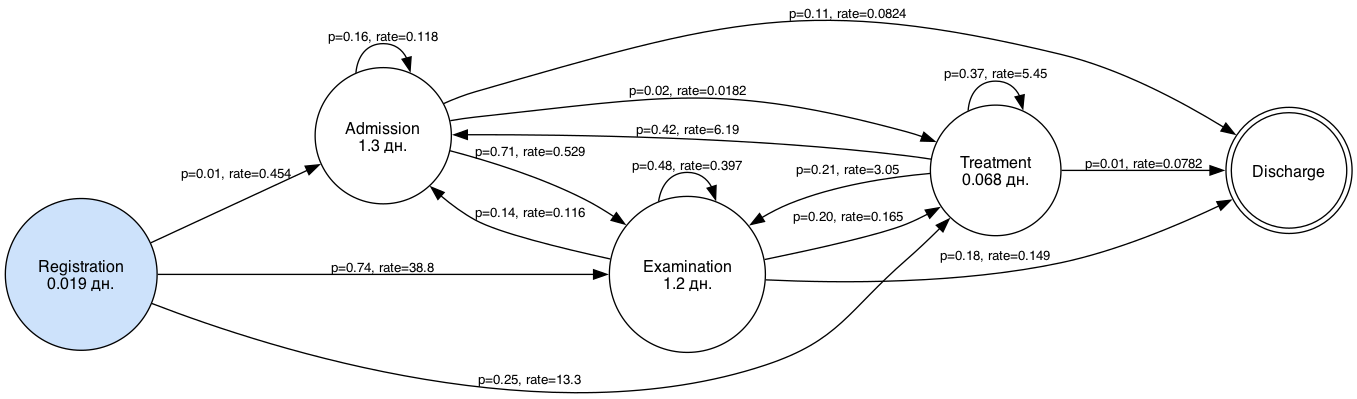

Сеть Петри с начальной и конечной маркировками.


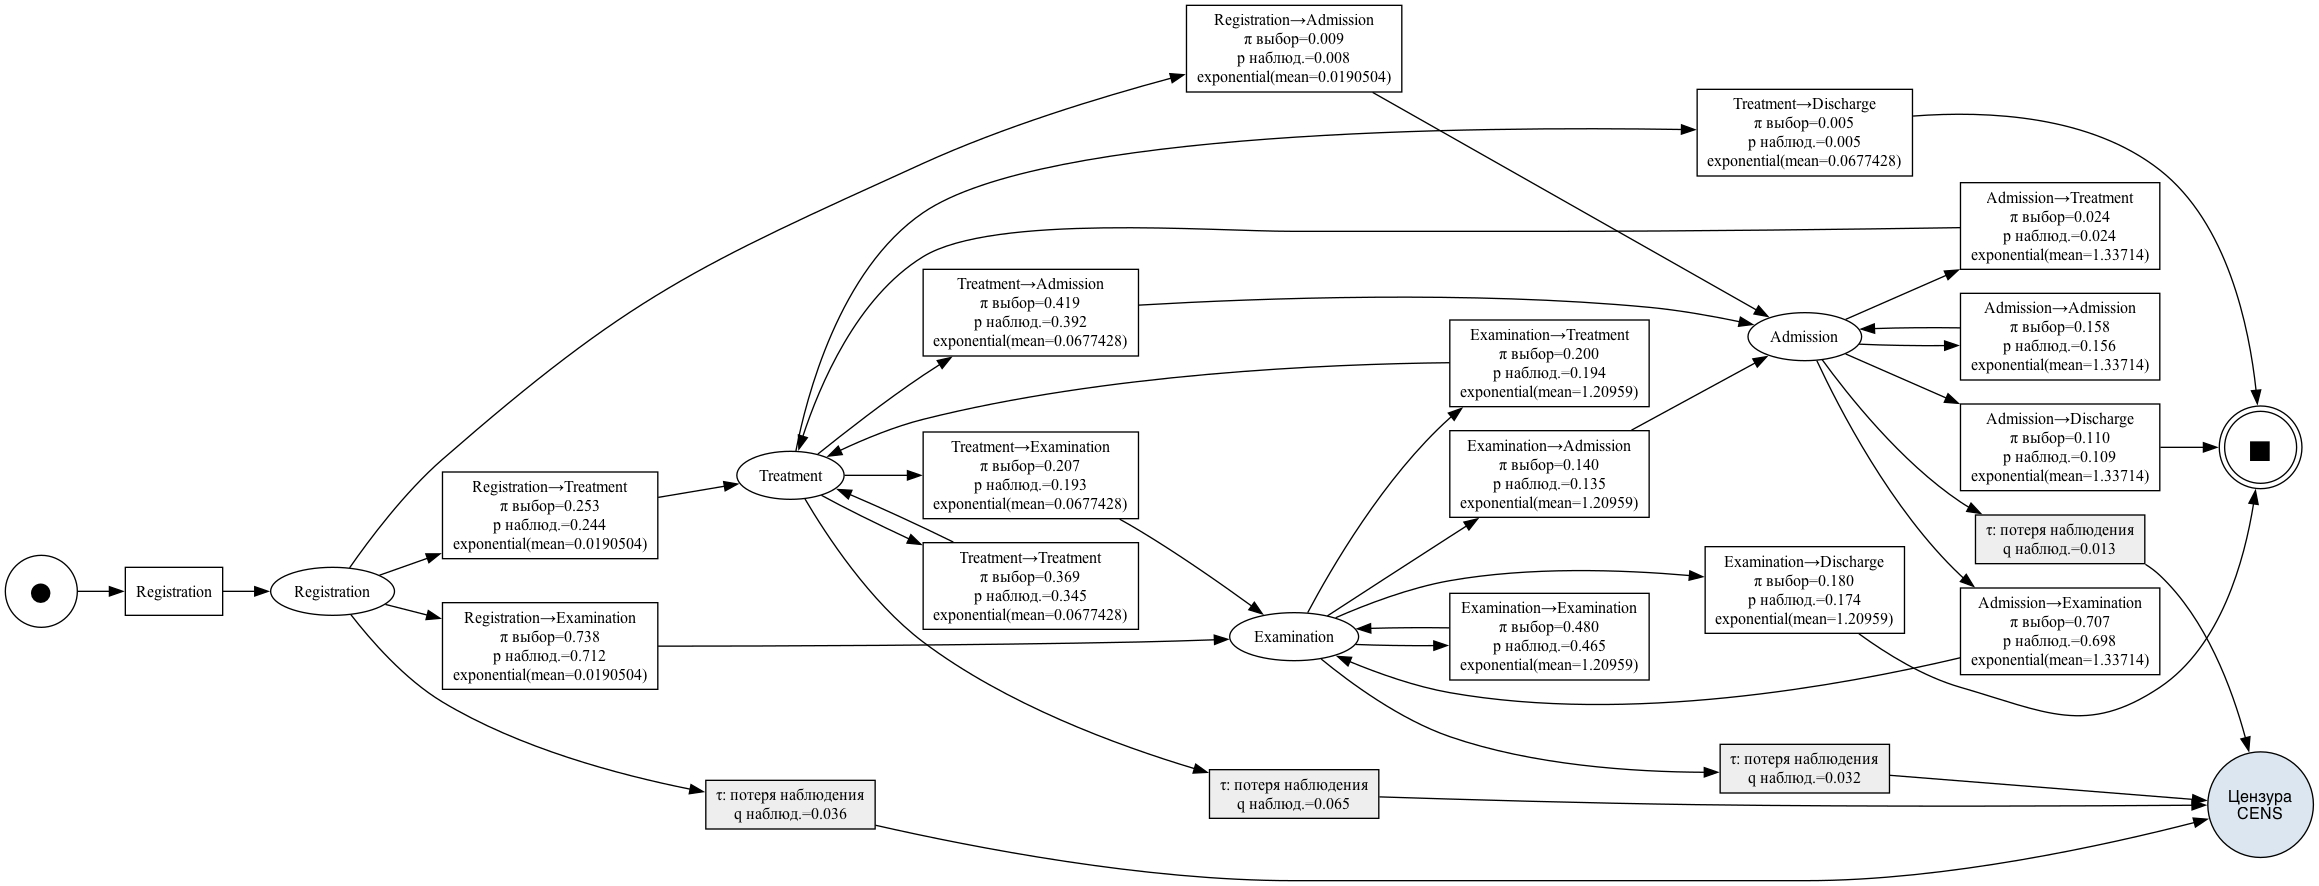

In [12]:
network = survpm.discover(train)
model = survpm.ProcessModel(network).fit(train, features=None, use_censoring=True)
petri, initial_marking, final_marking = model.to_pm4py(censoring=True)

print("Граф с вероятностями ветвей p и интенсивностями rate в обратных сутках.")
display(Image(model.plot().pipe(format="png")))
print("Сеть Петри с начальной и конечной маркировками.")
display(Image(draw_state_net(petri, initial_marking, final_marking).pipe(format="png")))

## 3. Интенсивности переходов из сети Петри

В сети состояний одна фишка, а у каждого перехода по одной входной и выходной дуге веса 1. Срабатывание служебного перехода `start` переносит фишку из `source` в `Registration`. Отсчёт времени начинается с этой маркировки. Переходы в `CENS` обозначают конец наблюдения. Цензурированные интервалы участвуют в оценивании модели, а в прогнозе учитываются переходы между клиническими местами.

Для каждого клинического перехода $e$ экспорт сохраняет `choice_probability` ($p_e$, вероятность выбора ветви) и среднее $m_e$ в `time_distribution`. Это среднее время до следующего срабатывания при конкуренции всех переходов из данного места, в сутках. При постоянных интенсивностях $\Lambda_i$ — их сумма в месте $i$, $m_e=1/\Lambda_i$ и $p_e=r_e/\Lambda_i$. Поэтому интенсивность перехода $r_e=p_e/m_e$ измеряется в обратных сутках. Для каждой пары мест $i,j$ складываем интенсивности её переходов: $r_{ij}=\sum_{e:i\to j}p_e/m_e$. Петли входят в эту сумму наравне с остальными переходами.

Например, для `Registration → Examination` на рисунке $p_e\approx0.738$ и $m_e\approx0.01905$ суток. Их отношение даёт около $39$ срабатываний на сутки экспозиции. Код использует параметры из свойств перехода с полной точностью.

Читаем места из дуг, а параметры из свойств переходов, затем сверяем все полученные интенсивности с `model.edges_table()`.

---

**中文翻译**

## 3. 从 Petri 网提取变迁速率

网中只有一个令牌，每条变迁各有一条入弧和一条出弧，权重均为 1。辅助变迁 `start` 发射时，将令牌从 `source` 移到 `Registration`，计时从这个标记开始。通向 `CENS` 的变迁表示观察结束。右删失的等待区间参与模型拟合，预测使用临床库所之间的变迁。

对每条临床变迁 $e$，导出时在 `choice_probability` 中保存分支选择概率 $p_e$，在 `time_distribution` 中保存平均等待时间 $m_e$。这里的平均等待时间指从进入该库所到其所有出变迁竞争后首次发射的平均时长，单位为天。在常速率模型中，$\Lambda_i$ 是库所 $i$ 的出变迁总速率，有 $m_e=1/\Lambda_i$ 和 $p_e=r_e/\Lambda_i$。因此，变迁速率 $r_e=p_e/m_e$ 的单位为每天。对每对库所 $i,j$，将连接这对库所的同向变迁速率相加，得到 $r_{ij}=\sum_{e:i\to j}p_e/m_e$。自环按同一规则计入。

例如，图中的 `Registration → Examination` 有 $p_e\approx0.738$、$m_e\approx0.01905$ 天，两者之比给出的发射速率约为每天 $39$ 次。代码直接使用变迁属性中未经显示舍入的参数。

根据弧读取起止库所，从变迁属性提取参数，再将所得速率逐一与 `model.edges_table()` 核对。

In [13]:
from pm4py.objects.petri_net import semantics

[source] = initial_marking
[start_transition] = semantics.enabled_transitions(petri, initial_marking)
registration_marking = semantics.execute(start_transition, petri, initial_marking)
[registration] = registration_marking
[terminal] = final_marking
assert start_transition.name == "start" and (registration.name, terminal.name) == (START, END)
assert initial_marking[source] == registration_marking[registration] == final_marking[terminal] == 1

states = sorted(p.name for p in petri.places if p not in (source, terminal) and p.name != CENSORED)
destinations = [*states, terminal.name]
rows = []
for transition in petri.transitions:
    [incoming], [outgoing] = transition.in_arcs, transition.out_arcs
    assert incoming.weight == outgoing.weight == 1
    src, dst = incoming.source.name, outgoing.target.name
    if transition is start_transition or dst == CENSORED:
        continue
    assert src in states and dst in destinations
    family, params = transition.properties["time_distribution"]
    probability, mean = transition.properties["choice_probability"], params["mean"]
    assert family == "exponential" and np.isfinite(mean) and mean > 0
    assert 0.0 <= probability <= 1.0
    rows.append((src, dst, probability / mean))

keys = ["src", "dst"]
petri_rates = pd.DataFrame(rows, columns=[*keys, "rate"]).groupby(keys)["rate"].sum()
model_rates = model.edges_table().groupby(keys)["rate"].sum()
pd.testing.assert_series_equal(petri_rates, model_rates, check_exact=False, rtol=1e-12, atol=0.)
rates = petri_rates.unstack().reindex(index=states, columns=destinations).fillna(0.).to_numpy()

n_loops = sum(src == dst for src, dst in petri_rates.index)
print(f"Мест до выписки — {len(states)}, направленных пар — {len(petri_rates)}, петель — {n_loops}.")
print("Интенсивности из сети Петри совпали с оценками модели для всех пар мест.")

Мест до выписки — 4, направленных пар — 15, петель — 3.
Интенсивности из сети Петри совпали с оценками модели для всех пар мест.


## 4. От интенсивностей к вероятности остаться без выписки

Пусть $D_i(u)$ — вероятность, что после входа в $i$ ещё не было ни одного срабатывания к моменту $u$. Для оценённых постоянных интенсивностей $\lambda_{ij}(u)=r_{ij}$ и $\Lambda_i=\sum_j r_{ij}$. Поэтому $D_i(u)=\exp[-\int_0^u\sum_j\lambda_{ij}(v)\,\mathrm dv]=e^{-\Lambda_i u}$, и ядро первого шага из лекции (`eq:local-surv`) принимает вид

$$
Q_{ij}(t)=\int_0^t D_i(u)\lambda_{ij}(u)\,\mathrm du
=r_{ij}\int_0^t e^{-\Lambda_i u}\,\mathrm du
=\frac{r_{ij}}{\Lambda_i}\bigl(1-e^{-\Lambda_i t}\bigr).
$$

При $\Lambda_i=0$ ядро равно нулю. Пусть $b$ — место выписки, $\mathcal U$ — множество остальных клинических мест, а $F_i(t)$ — вероятность впервые достигнуть $b$ за время $t$. По уравнению первого шага (`eq:renewal`)

$$
F_i(t)=Q_{ib}(t)+\sum_{j\in\mathcal U}\int_{[0,t]}F_j(t-u)\,\mathrm dQ_{ij}(u).
$$

На равномерной сетке с шагом $h$ обозначим $d_i=e^{-\Lambda_i h}$ и $w_{ij}=Q_{ij}(h)$. Масса первого шага в $k$-м интервале равна $d_i^{k-1}w_{ij}$. Для перехода в промежуточное место оставшееся время считаем по правой границе интервала. Поскольку все более поздние интервалы получают один множитель $d_i$ при сдвиге на шаг, рекурсия сводится к

$$
F_i(nh)\approx w_{ib}+d_iF_i((n-1)h)
+\sum_{j\in\mathcal U}w_{ij}F_j((n-1)h),\qquad F_i(0)=0.
$$

Член $d_iF_i((n-1)h)$ соответствует ожиданию без срабатывания в первом интервале, а $w_{ii}$ — срабатыванию петли. Для прогноза из маркировки `Registration` берём $S(t)=1-F_{\mathrm{Registration}}(t)$ (`eq:targets`). Используем один шаг $h=1/64$ суток. Между узлами сетки значение интерполируется линейно.

---

**中文翻译**

## 4. 从变迁速率到未出院概率

设 $D_i(u)$ 为进入库所 $i$ 后，截至时刻 $u$ 尚未发生任何变迁的概率。拟合模型采用常速率 $\lambda_{ij}(u)=r_{ij}$，且 $\Lambda_i=\sum_j r_{ij}$。因此 $D_i(u)=\exp[-\int_0^u\sum_j\lambda_{ij}(v)\,\mathrm dv]=e^{-\Lambda_i u}$，讲义中的首步核（`eq:local-surv`）可写为

$$
Q_{ij}(t)=\int_0^t D_i(u)\lambda_{ij}(u)\,\mathrm du
=r_{ij}\int_0^t e^{-\Lambda_i u}\,\mathrm du
=\frac{r_{ij}}{\Lambda_i}\bigl(1-e^{-\Lambda_i t}\bigr).
$$

当 $\Lambda_i=0$ 时，首步核为零。设 $b$ 为出院库所，$\mathcal U$ 为其余临床库所的集合，$F_i(t)$ 为从 $i$ 出发在时间 $t$ 内首次到达 $b$ 的概率。按首步方程（`eq:renewal`）有

$$
F_i(t)=Q_{ib}(t)+\sum_{j\in\mathcal U}\int_{[0,t]}F_j(t-u)\,\mathrm dQ_{ij}(u).
$$

在步长为 $h$ 的均匀网格上，记 $d_i=e^{-\Lambda_i h}$，$w_{ij}=Q_{ij}(h)$。首步落入第 $k$ 个区间的概率质量为 $d_i^{k-1}w_{ij}$。当变迁到达中间库所时，按其所在区间的右端点计算剩余时间。将区间向后移一格时，核的概率质量统一乘以 $d_i$，所以递推式可写为

$$
F_i(nh)\approx w_{ib}+d_iF_i((n-1)h)
+\sum_{j\in\mathcal U}w_{ij}F_j((n-1)h),\qquad F_i(0)=0.
$$

项 $d_iF_i((n-1)h)$ 对应在第一格等待且无变迁发射，$w_{ii}$ 对应自环发射。从 `Registration` 标记出发的未出院概率为 $S(t)=1-F_{\mathrm{Registration}}(t)$（`eq:targets`）。固定步长为 $h=1/64$ 天，格点之间采用线性插值。

In [14]:
def discharge_cdf(rates, horizon, step):
    n_steps = round(horizon / step)
    assert np.isclose(n_steps * step, horizon)
    total = rates.sum(axis=1)
    no_jump = np.exp(-total * step)
    kernel_scale = np.divide(
        -np.expm1(-total * step), total, out=np.zeros_like(total), where=total > 0,
    )
    jump = rates * kernel_scale[:, None]
    to_discharge = jump[:, -1]
    within_transient = jump[:, :-1] + np.diag(no_jump)

    cdf = np.zeros((n_steps + 1, len(total)))
    for n in range(1, n_steps + 1):
        cdf[n] = to_discharge + within_transient @ cdf[n - 1]
    return np.arange(n_steps + 1) * step, cdf


HORIZON, STEP = 30., 1 / 64
times, cdf = discharge_cdf(rates, HORIZON, STEP)
assert np.isfinite(cdf).all() and np.all((cdf >= -1e-12) & (cdf <= 1 + 1e-12))
assert np.all(np.diff(cdf, axis=0) >= -1e-12)
survival = 1 - cdf[:, states.index(registration.name)]
assert survival[0] == 1.

# Для модели с одним переходом в выписку известна точная кривая.
_, check_cdf = discharge_cdf(np.array([[0., 0.4]]), HORIZON, STEP)
np.testing.assert_allclose(1 - check_cdf[:, 0], np.exp(-0.4 * times), atol=1e-12)


def survival_at(days):
    days = np.asarray(days, dtype=float)
    if not np.all(np.isfinite(days) & (0 <= days) & (days <= HORIZON)):
        raise ValueError("Горизонт должен быть от 0 до 30 суток.")
    return np.interp(days, times, survival)

## 5. Сравнение с отложенными случаями

По исходным отметкам времени считаем длительность от первой регистрации до первой выписки или последней записи. В оценке Нельсона–Аалена $\widehat H(t)=\sum_{u\le t}d(u)/Y(u^-)$ число выписок $d(u)$ делится на число случаев под риском непосредственно перед $u$. Цензурированные в тот же момент входят в $Y(u^-)$, а вклад в $d(u)$ дают только выписки. Эмпирическая кривая равна $\exp[-\widehat H(t)]$.

Сравнение ограничено общим диапазоном наблюдений и прогноза. Под графиком показано, сколько случаев ещё под риском. Эмпирическая оценка опирается на предположение о независимом цензурировании, а сравнение характеризует калибровку на уровне группы.

---

**中文翻译**

## 5. 与留出病例对比

根据原始时间戳，计算从首次登记到首次出院或最后一条观察记录的随访时长。在 Nelson–Aalen 估计 $\widehat H(t)=\sum_{u\le t}d(u)/Y(u^-)$ 中，每个出院时刻 $u$ 的出院人数 $d(u)$ 除以该时刻跳变前的在险人数 $Y(u^-)$。同一时刻删失的病例仍计入 $Y(u^-)$，只有出院病例计入 $d(u)$。经验曲线为 $\exp[-\widehat H(t)]$。

对比范围为随访与预测覆盖的共同时间区间。主图下方显示各时刻仍在险的病例数。经验估计依赖独立删失假设，曲线比较反映群体层面的校准。

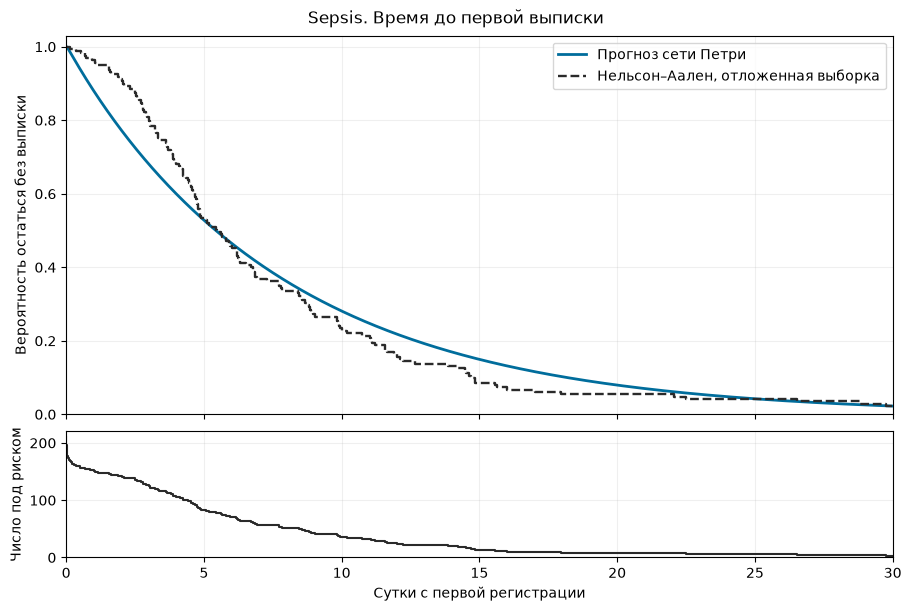

 Сутки  Сеть Петри  Нельсон–Аален  Под риском
     1    0.879951       0.962917         152
     3    0.680600       0.809399         126
     7    0.410303       0.367912          57
    14    0.169586       0.131180          20
    30    0.022511       0.022470           3


In [15]:
events = raw.loc[raw["case_id"].isin(test_ids)].sort_values(["case_id", "timestamp"], kind="stable")
after_registration = events["activity"].eq(START).groupby(events["case_id"]).cummax()
events = events.loc[after_registration]
by_case = events.groupby("case_id")["timestamp"]
entry = by_case.first()
discharge = events.loc[events["activity"].eq(END)].groupby("case_id")["timestamp"].first()
discharge = discharge.reindex(entry.index)
ended = discharge.fillna(by_case.last())
observed_event = discharge.notna()
duration = (ended - entry) / pd.Timedelta(days=1)

assert set(entry.index) == test_ids and duration.ge(0).all()
observation = test.observation.set_index("case_id").loc[entry.index]
np.testing.assert_array_equal(ended, observation["end"])
np.testing.assert_array_equal(observed_event, observation["event"].astype(bool))

counts = observed_event.groupby(duration, sort=True).agg(ends="size", events="sum")
# Из множества под риском исключаем только завершивших наблюдение строго раньше u.
counts["risk"] = len(duration) - counts["ends"].cumsum().shift(fill_value=0)
jumps = counts.loc[counts["events"].gt(0)]
jump_times = jumps.index.to_numpy()
cum_hazard = np.r_[0., (jumps["events"] / jumps["risk"]).cumsum().to_numpy()]
followup = np.sort(duration.to_numpy())


def empirical_survival(days):
    index = np.searchsorted(jump_times, days, side="right")
    return np.exp(-cum_hazard[index])


def risk_before(days):
    return len(followup) - np.searchsorted(followup, days, side="left")


np.testing.assert_array_equal(risk_before(counts.index), counts["risk"])
overlap = min(HORIZON, followup[-1])
empirical_days = np.unique(np.r_[0., jump_times[jump_times <= overlap], overlap])
risk_days = np.unique(np.r_[0., followup[followup <= overlap], overlap])

fig, (ax, risk_ax) = plt.subplots(
    2, 1, figsize=(9, 6), sharex=True, layout="constrained",
    gridspec_kw={"height_ratios": [3, 1]},
)
fig.suptitle("Sepsis. Время до первой выписки")
ax.plot(times, survival, color="#006D9C", lw=2, label="Прогноз сети Петри")
ax.step(empirical_days, empirical_survival(empirical_days), where="post", color="#2A2A2A",
        linestyle="--", lw=1.7, label="Нельсон–Аален, отложенная выборка")
ax.set(ylabel="Вероятность остаться без выписки", ylim=(0, 1.03))
ax.legend()
risk_ax.step(risk_days, risk_before(risk_days), where="pre", color="#2A2A2A")
risk_ax.set(xlabel="Сутки с первой регистрации", ylabel="Число под риском",
            xlim=(0, overlap), ylim=(0, None))
for axis in (ax, risk_ax):
    axis.grid(alpha=0.2)
plt.show()

days = np.array([1, 3, 7, 14, 30])
days = days[days <= overlap]
comparison = pd.DataFrame({
    "Сутки": days,
    "Сеть Петри": survival_at(days),
    "Нельсон–Аален": empirical_survival(days),
    "Под риском": risk_before(days),
})
print(comparison.to_string(index=False, float_format="{:.6f}".format))